# Reporte del clasificador señal vs background

Este notebook carga el modelo entrenado con `train_classifier.py`, reconstruye el conjunto de **test** (el mismo que el modelo nunca vio durante el entrenamiento) y reporta su desempeño.

**Secciones:**
1. Configuración y datos 
2. Métricas
3. Matriz de confusión
4. Curva ROC
5. Distribución del score
6. Importancia de features
7. Variables principales

## 1. Configuración y datos

In [24]:
SIGNAL_CSV = '../data/signal_vars.csv'
BKG_CSV    = '../data/bkg_vars.csv'
MODEL_PATH = '../model/classifier_model.joblib'
THRESHOLD  = 0.5

In [10]:
import joblib
import numpy as np
import pandas as pd
import sklearn
import warnings
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

FILL = -999.0

In [19]:
bundle = joblib.load(MODEL_PATH)
model, features = bundle["model"], bundle["features"]
seed, test_size = bundle["seed"], bundle["test_size"]

print(f"Features usadas ({len(features)}):" + '\n  * ' + '\n  * '.join(features))
print(f"Iteraciones del modelo: {model.n_iter_}")
print(f"seed = {seed} | test_size = {test_size}")

Features usadas (13):
  * photon1_pt
  * photon1_eta
  * photon1_phi
  * photon2_pt
  * photon2_eta
  * photon2_phi
  * m_gg
  * diphoton_pt
  * diphoton_eta
  * delta_r_gg
  * n_photons
  * n_jets
  * missing_et
Iteraciones del modelo: 144
seed = 42 | test_size = 0.2


In [20]:
sig = pd.read_csv(SIGNAL_CSV); sig["label"] = 1
bkg = pd.read_csv(BKG_CSV);    bkg["label"] = 0

df = pd.concat([sig, bkg], ignore_index=True).replace(FILL, np.nan)
X, y = df[features], df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, stratify=y, random_state=seed)

summary = pd.DataFrame({
    "total": y.value_counts(),
    "train": y_train.value_counts(),
    "test":  y_test.value_counts(),
}).rename(index={1: "signal", 0: "background"}).loc[["signal", "background"]]
summary

,total,train,test
label,,,
signal,10000,8000,2000
background,10000,8000,2000


In [21]:
nan_frac = (df.groupby("label")[features].apply(lambda g: g.isna().mean()).T
              .rename(columns={1: "signal", 0: "background"}))
nan_frac[(nan_frac > 0).any(axis=1)].round(3)

label,background,signal
photon1_pt,0.165,0.042
photon1_eta,0.165,0.042
photon1_phi,0.165,0.042
photon2_pt,0.605,0.375
photon2_eta,0.605,0.375
photon2_phi,0.605,0.375
m_gg,0.605,0.375
diphoton_pt,0.605,0.375
diphoton_eta,0.605,0.375
delta_r_gg,0.605,0.375


## 2. Métricas

In [ ]:
p_train = model.predict_proba(X_train)[:, 1]
p_test  = model.predict_proba(X_test)[:, 1]
pred_test = (p_test > THRESHOLD).astype(int)

auc_train = roc_auc_score(y_train, p_train)
auc_test  = roc_auc_score(y_test, p_test)

print(f"AUC train: {auc_train:.4f}")
print(f"AUC test : {auc_test:.4f}")
print(f"Accuracy (test, umbral {THRESHOLD}): {accuracy_score(y_test, pred_test):.4f}")
if auc_train - auc_test > 0.02: print("-> Posible overfitting: AUC train bastante mayor que AUC test.")
print()
print(classification_report(y_test, pred_test, target_names=["background", "signal"]))

AUC train: 0.9979
AUC test : 0.9949
Accuracy (test, umbral 0.5): 0.9700

              precision    recall  f1-score   support

  background       0.97      0.97      0.97      2000
      signal       0.97      0.96      0.97      2000

    accuracy                           0.97      4000
   macro avg       0.97      0.97      0.97      4000
weighted avg       0.97      0.97      0.97      4000



In [27]:
t = df.loc[X_test.index]
mask = (t["n_photons"] >= 2).to_numpy()
print(f"Eventos de test con de 1 fotón: {mask.sum()} de {len(mask)} ({mask.mean():.1%})")
if len(np.unique(y_test[mask])) == 2:
    print(f"AUC test (>= 2 fotones): {roc_auc_score(y_test[mask], p_test[mask]):.4f}")
    print(f"AUC test (< 2 fotones) : "
          f"{roc_auc_score(y_test[~mask], p_test[~mask]) if len(np.unique(y_test[~mask])) == 2 else float('nan'):.4f}")

Eventos de test con de 1 fotón: 2045 de 4000 (51.1%)
AUC test (>= 2 fotones): 0.9992
AUC test (< 2 fotones) : 0.9837


## 3. Matriz de confusión

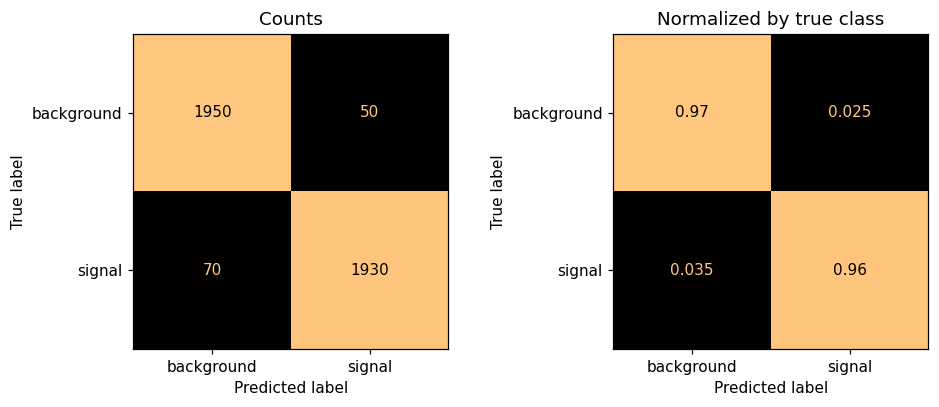

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, norm, title in zip(axes, [None, "true"], ["Counts", "Normalized by true class"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred_test, normalize=norm, display_labels=["background", "signal"],
        cmap="copper", ax=ax, colorbar=False)
    ax.set_title(title); ax.grid(False)
plt.tight_layout(); plt.show()

## 4. Curva ROC

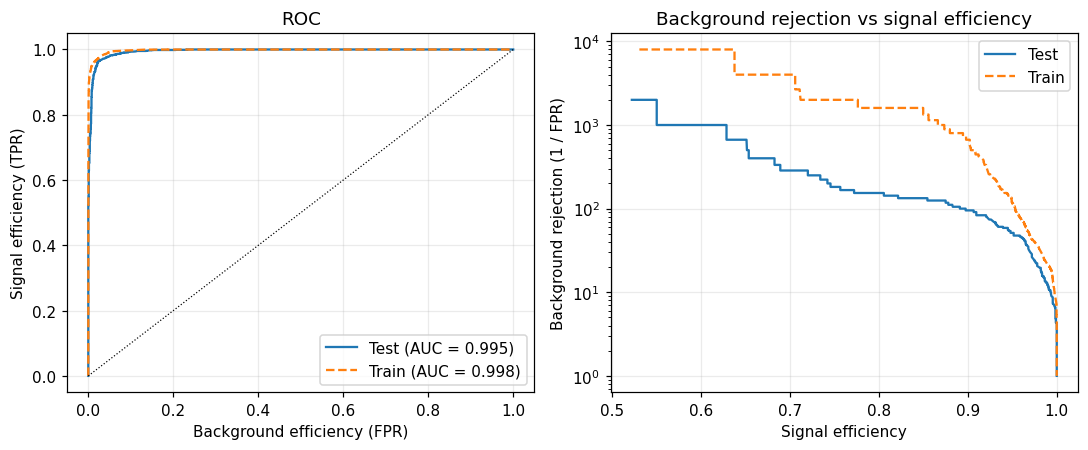

In [30]:
fpr, tpr, _     = roc_curve(y_test, p_test)
fpr_tr, tpr_tr, _ = roc_curve(y_train, p_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

ax = axes[0]
ax.plot(fpr, tpr, label=f"Test (AUC = {auc_test:.3f})")
ax.plot(fpr_tr, tpr_tr, "--", label=f"Train (AUC = {auc_train:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set_xlabel("Background efficiency (FPR)"); ax.set_ylabel("Signal efficiency (TPR)")
ax.legend(); ax.set_title("ROC")

ax = axes[1]
m, mt = fpr > 0, fpr_tr > 0
ax.plot(tpr[m], 1 / fpr[m], label="Test")
ax.plot(tpr_tr[mt], 1 / fpr_tr[mt], "--", label="Train")
ax.set_yscale("log")
ax.set_xlabel("Signal efficiency"); ax.set_ylabel("Background rejection (1 / FPR)")
ax.legend(); ax.set_title("Background rejection vs signal efficiency")

plt.tight_layout(); plt.show()

## 5. Distribución del score

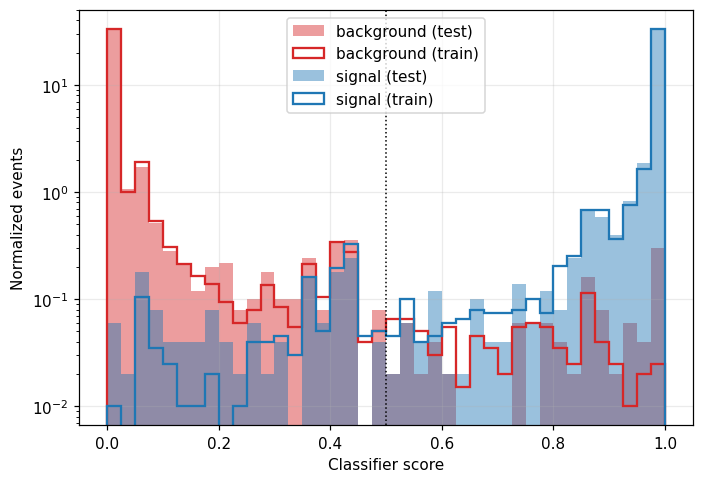

KS signal    : estadístico = 0.0194, p-valor = 0.581
KS background: estadístico = 0.0165, p-valor = 0.772


In [31]:
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(6.5, 4.5))

for lab, name, c in [(0, "background", "tab:red"), (1, "signal", "tab:blue")]:
    ax.hist(p_test[y_test == lab], bins=bins, density=True, alpha=0.45,
            color=c, label=f"{name} (test)")
    ax.hist(p_train[y_train == lab], bins=bins, density=True, histtype="step",
            color=c, lw=1.5, label=f"{name} (train)")
ax.axvline(THRESHOLD, color="k", ls=":", lw=1)
ax.set_yscale("log"); ax.set_xlabel("Classifier score"); ax.set_ylabel("Normalized events")
ax.legend(); plt.tight_layout(); plt.show()

# Test de Kolmogorov-Smirnov train vs test (p-valores bajos pueden ser producto de overfitting)
for lab, name in [(1, "signal"), (0, "background")]:
    ks = ks_2samp(p_train[y_train == lab], p_test[y_test == lab])
    print(f"KS {name:10s}: estadístico = {ks.statistic:.4f}, p-valor = {ks.pvalue:.3f}")

## 6. Importancia de features

Importancia por permutación sobre el conjunto de test: cuánto cae el AUC al barajar cada variable.

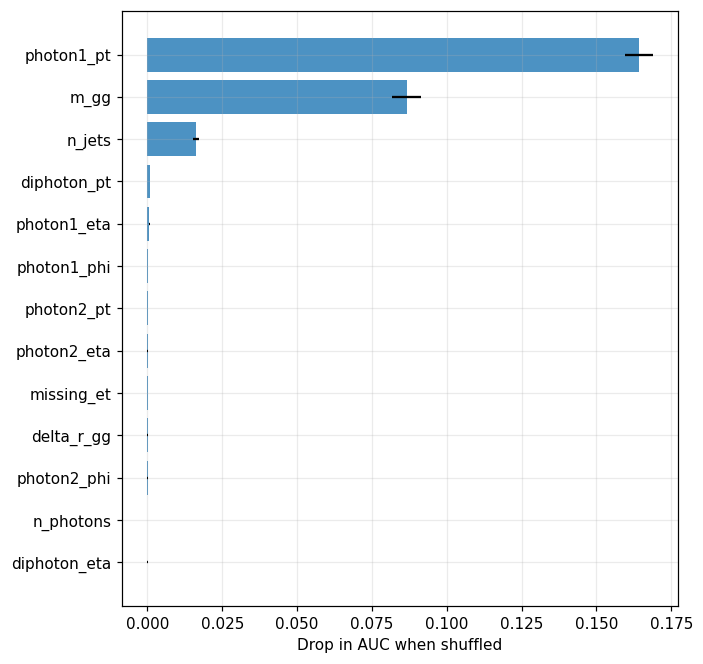

,mean,std
photon1_pt,0.1642,0.0045
m_gg,0.0866,0.0048
n_jets,0.0162,0.0010
diphoton_pt,0.0009,0.0001
photon1_eta,0.0006,0.0002
photon1_phi,0.0002,0.0001
photon2_pt,0.0002,0.0001
photon2_eta,0.0001,0.0001
missing_et,0.0001,0.0001
delta_r_gg,0.0001,0.0001


In [32]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=seed, n_jobs=-1)
imp = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                    index=features).sort_values("mean"))

fig, ax = plt.subplots(figsize=(6.5, 0.38 * len(features) + 1.2))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color="tab:blue", alpha=0.8)
ax.set_xlabel("Drop in AUC when shuffled"); plt.tight_layout(); plt.show()
imp.sort_values("mean", ascending=False).round(4)

## 7. Variables principales: señal vs background

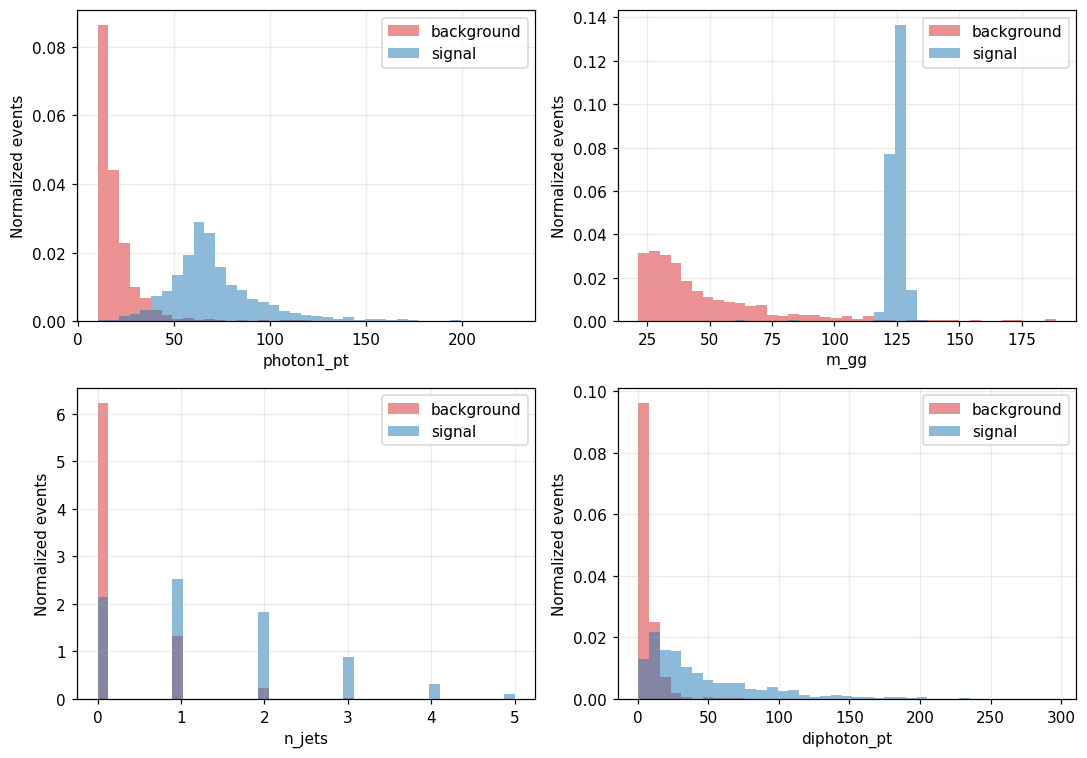

In [33]:
top = list(imp.sort_values("mean", ascending=False).index[:4])
Xt = X_test.assign(label=y_test)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), top):
    vals = Xt[f].dropna()
    bins = np.linspace(vals.quantile(0.005), vals.quantile(0.995), 40)
    for lab, name, c in [(0, "background", "tab:red"), (1, "signal", "tab:blue")]:
        ax.hist(Xt.loc[Xt.label == lab, f].dropna(), bins=bins, density=True,
                alpha=0.5, color=c, label=name)
    ax.set_xlabel(f); ax.set_ylabel("Normalized events"); ax.legend()
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
plt.tight_layout(); plt.show()